# Avance 5. Ensambles heterogéneos: mezcla convexa y meta-aprendiz

**Inferencia de propiedades físicas de galaxias a partir de imágenes multibanda** · Instituto Tecnológico y de Estudios Superiores de Monterrey · Maestría en Inteligencia Artificial Aplicada · **Equipo 24** · Colaboración con el Instituto de Astronomía de la UNAM

| Integrante | Matrícula |
|---|---|
| Luz Copelia Minutti Pérez | A01796921 |
| Erick Alberto Bustos Cruz | A01378966 |
| José Florencio Maguey Peralta | A01796727 |

**Asesores:** Dr. Iván Reyes Amezcua (ITESM) · Dr. Héctor Hernández Toledo y Dr. José Antonio Vázquez Mata (IA-UNAM)

**Fase de CRISP-ML(Q):** 3, *Machine Learning Model Engineering* (Studer et al. 2021). **Avance 5:** modelo final.

## 1. Planteamiento

En el Avance 4 comparamos seis modelos individuales y vimos que ninguno domina en todas las propiedades: la ResNet50 con redshift estima mejor la masa, y DINOv3 con LoRA estima mejor la SFR y el D4000. Un **ensamble heterogéneo** combina arquitecturas distintas para aprovechar justamente eso. Según la descomposición de Krogh y Vedelsby (1995), el error de un ensamble es el error medio de sus miembros menos su desacuerdo, de modo que combinar modelos que se equivocan de formas distintas reduce el error por debajo del de cualquiera de ellos. Los ensambles homogéneos de ResNet50, que combinan semillas de una misma arquitectura, están en el cuaderno de Luz Minutti; en este construimos dos heterogéneos, con estrategias distintas.

La **mezcla convexa** (*blending*) es un promedio ponderado con pesos no negativos que suman uno, aprendidos en un conjunto de reserva (Breiman 1996). El **meta-aprendiz** (*stacking*) es un modelo que recibe las predicciones de todos los miembros y aprende a corregir su promedio (Wolpert 1992). Los dos se entrenan con el conjunto de validación como reserva, porque reentrenar cada red varias veces sobre pliegues del entrenamiento costaría horas de GPU por red. En sentido estricto, entrenar con una reserva es *blending* (Singh 2023); llamamos *stacking* al segundo porque su combinador es un modelo entrenado y no un promedio ponderado. Cada miembro es una familia de redes representada por el promedio de sus tres semillas, que es su capa homogénea; así el combinador ve pocas columnas y no se sobreajusta con 1,261 galaxias.

**Miembros.** Combinamos tres arquitecturas distintas que reciben la imagen y el redshift espectroscópico: DINOv3 con LoRA, ConvNeXt-Tiny y EfficientNet-B3, entrenadas en el cuaderno de modelos base. En validación son el primero, el segundo y el cuarto mejor modelo individual del equipo (criterios de 0.112, 0.120 y 0.129, con la media de tres semillas); el tercero es la ResNet50 E del modelo 1 (0.128). La ResNet50 no puede entrar a la combinación porque su cuaderno reporta métricas agregadas de validación, pero no exporta sus predicciones galaxia por galaxia ni predice el conjunto de prueba, y un combinador necesita la predicción de cada miembro para cada galaxia.

Como la validación ya sirvió para elegir la época de cada red, y ahora también para entrenar a los combinadores, usamos validación cruzada anidada (Cawley y Talbot 2010): el ciclo interno elige los hiperparámetros del combinador y el externo mide el desempeño en galaxias que no intervinieron en esa elección. En este cuaderno no se calcula ninguna métrica con el conjunto de prueba. Solo se guardan las predicciones de prueba de cada ensamble, ajustado con toda la validación, para que el cuaderno de comparación final las evalúe una sola vez, después de registrar el modelo elegido.

El avance se reparte en cuatro cuadernos de esta carpeta:

| Cuaderno | Contenido |
|---|---|
| `Ensambles_Homogeneos_ResNet50_D_E_vf.ipynb` | Ensambles homogéneos de ResNet50 (variantes D y E, tres semillas cada una) y búsqueda de sus pesos, evaluados en validación |
| `Modelos_Base_DINOv3_ConvNeXt_EfficientNet.ipynb` | Entrenamiento en GPU de los miembros nuevos y exportación de las predicciones de nuestras redes |
| `Ensambles_Heterogeneos_Mezcla_MetaAprendiz.ipynb` | Ensambles heterogéneos: mezcla convexa y meta-aprendiz, con su optimización y su validación anidada |
| `Avance5.24.ipynb` | Comparación final de los modelos individuales y de los ensambles, selección del modelo final y evaluación en prueba |

**El interruptor de la pista.** Trabajamos con dos pistas, que se separan con una sola variable. La pista `con_redshift` usa modelos que reciben el redshift espectroscópico como entrada, igual que la variante E de ResNet50. La pista `solo_imagen` usa modelos que solo reciben la imagen, que es la situación de la mayoría de las galaxias a las que queremos extender las estimaciones. Con `PISTA = "con_redshift"` (valor por defecto) el cuaderno construye los ensambles de la primera; al cambiar la variable construye los de la segunda, con exactamente el mismo código. El cuaderno de comparación final debe ejecutarse con la misma pista.

## 2. Parámetros

| Parámetro | Valor | Significado |
|---|---|---|
| `PISTA` | `con_redshift` | Interruptor de la pista: `con_redshift` o `solo_imagen` |
| `PLIEGUES_EXTERNOS` | 5 | Pliegues de la validación cruzada que mide el desempeño de cada combinador |
| `REPETICIONES` | 3 | Veces que se repite la validación cruzada con otra partición, para medir su variación |
| `PLIEGUES_INTERNOS` | 4 | Pliegues del ciclo interno, donde se eligen los hiperparámetros |
| `PRUEBAS_STACKING` | 40 | Configuraciones que prueba la búsqueda de Optuna del meta-aprendiz en cada pliegue externo |
| `N_REMUESTREOS` | 2000 | Remuestreos *bootstrap* para los intervalos de confianza |

| Pista | Familias que se combinan en los heterogéneos |
|---|---|
| `con_redshift` | `dinov3_z`, `convnext_z`, `efficientnet_z` |
| `solo_imagen` | `dinov3_imagen`, `convnext_imagen` y, si se entrenó, `efficientnet_imagen` |

In [1]:
import os
variable_entorno = os.environ.get          # las variables MA_* solo se usan en la prueba local reducida

# ------------------------------------------------------------------------------------------------
# INTERRUPTOR DE LA PISTA: "con_redshift" (redshift espectroscópico como entrada) o "solo_imagen".
PISTA = "con_redshift"
# ------------------------------------------------------------------------------------------------
PISTA = variable_entorno("MA_PISTA", PISTA)
PISTAS = {"con_redshift": {"heterogeneo": ["dinov3_z", "convnext_z", "efficientnet_z"], "otros": [],
                           "redshift_en_meta": True, "descripcion": "con el redshift espectroscópico como entrada"},
          "solo_imagen": {"heterogeneo": ["dinov3_imagen", "convnext_imagen", "efficientnet_imagen"], "otros": [],
                          "redshift_en_meta": False, "descripcion": "solo con la imagen"}}
if PISTA not in PISTAS:
    raise ValueError(f"PISTA debe ser una de {list(PISTAS)}")
OBJETIVOS = ("log_mstar", "log_sfr", "d4000")
NOMBRES = {"log_mstar": "log M* [dex]", "log_sfr": "log SFR [dex]", "d4000": "D4000"}
CORTO = {"log_mstar": "M*", "log_sfr": "SFR", "d4000": "D4000"}
NOMBRE_H1, NOMBRE_H2 = "Heterogéneo 1: mezcla convexa", "Heterogéneo 2: meta-aprendiz"
ARCHIVO_H1, ARCHIVO_H2 = "h1_mezcla_convexa", "h2_meta_aprendiz"

REDSHIFT_EN_META = PISTAS[PISTA]["redshift_en_meta"]       # el redshift solo puede ser entrada del meta-aprendiz si la pista lo usa
PLIEGUES_EXTERNOS = int(variable_entorno("MA_PLIEGUES_EXTERNOS", "5"))
REPETICIONES = int(variable_entorno("MA_REPETICIONES", "3"))
PLIEGUES_INTERNOS = int(variable_entorno("MA_PLIEGUES_INTERNOS", "4"))
PRUEBAS_STACKING = int(variable_entorno("MA_PRUEBAS_STACKING", "40"))
N_REMUESTREOS = int(variable_entorno("MA_REMUESTREOS", "2000"))
SEMILLA_ANIDADA = 7
N_TRABAJOS = int(variable_entorno("MA_TRABAJOS", "-1"))
print(f"Pista: {PISTA} ({PISTAS[PISTA]['descripcion']})")

Pista: con_redshift (con el redshift espectroscópico como entrada)


## 3. Entorno

Este cuaderno no necesita GPU ni acceso a las imágenes: trabaja con las predicciones que cada red exportó en un formato común (un archivo pequeño por familia y semilla, con las galaxias de validación y de prueba), que están en el repositorio. Descargamos el código del equipo para ligar los resultados a una versión concreta.

In [2]:
import sys, json, time, subprocess, platform, warnings, hashlib
from pathlib import Path
from datetime import datetime, timezone

EN_COLAB = "google.colab" in sys.modules
URL_REPOSITORIO = "https://github.com/erteck/InferenciaPropiedadesFisicas.git"
CARPETA_REPOSITORIO = Path(variable_entorno("MA_CARPETA_REPOSITORIO", "/content/InferenciaPropiedadesFisicas"))
if EN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna>=4"], check=True)
    if not CARPETA_REPOSITORIO.exists():
        subprocess.run(["git", "clone", "-q", URL_REPOSITORIO, str(CARPETA_REPOSITORIO)], check=True)
    subprocess.run(["git", "-C", str(CARPETA_REPOSITORIO), "pull", "-q"], check=True)
elif not (CARPETA_REPOSITORIO / "src").exists():
    CARPETA_REPOSITORIO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "modelos_alternativos").exists())
sys.path.insert(0, str(CARPETA_REPOSITORIO))
COMMIT = subprocess.run(["git", "-C", str(CARPETA_REPOSITORIO), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()

warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display
from src.modelos_alternativos import ensambles, evaluacion, predicciones

CARPETA_PREDICCIONES = Path(variable_entorno("MA_CARPETA_PREDICCIONES", str(CARPETA_REPOSITORIO / "Avance 5. Modelo final" / "predicciones")))
CARPETA_ENTREGA = CARPETA_PREDICCIONES.parent
CARPETA_HETEROGENEOS = CARPETA_ENTREGA / "ensambles_heterogeneos"
pd.set_option("display.precision", 4, "display.max_columns", 40, "display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
print("Python", platform.python_version(), "· commit", COMMIT[:12], "·", CARPETA_PREDICCIONES)

Python 3.10.13 · commit 6567def00d82 · /Users/erteck/Documents/GitHub/InferenciaPropiedadesFisicas/Avance 5. Modelo final/predicciones


In [3]:
import optuna
print("optuna", optuna.__version__)

optuna 5.0.0


## 4. Predicciones de los miembros

Leemos las predicciones de todas las redes y las alineamos por el identificador de cada galaxia (`mangaid`), nunca por posición. Si alguna red no trae predicción para una galaxia, esa galaxia se descarta para todas, de modo que todos los modelos se comparan sobre exactamente la misma muestra. También se comprueba que las etiquetas y el redshift coincidan entre archivos. La métrica principal, el promedio entre propiedades del MSE normalizado por la desviación de entrenamiento (cuanto menor, mejor), usa una escala que viene en un archivo aparte porque este cuaderno no tiene acceso al catálogo.

In [4]:
TABLA = predicciones.leer_carpeta(CARPETA_PREDICCIONES)
ESCALA = predicciones.leer_escala(CARPETA_PREDICCIONES)
CONFIGURACION = PISTAS[PISTA]
CANDIDATAS = CONFIGURACION["heterogeneo"] + CONFIGURACION["otros"]
DISPONIBLES = [f for f in CANDIDATAS if f in set(TABLA[TABLA.particion == "Validation"].familia) and f in set(TABLA[TABLA.particion == "Test"].familia)]
FALTAN = [f for f in CANDIDATAS if f not in DISPONIBLES]
if FALTAN:
    print("Aviso: no hay predicciones de validación y de prueba para:", FALTAN, "· se trabaja sin ellas")
FAMILIAS_HETEROGENEO = [f for f in CONFIGURACION["heterogeneo"] if f in DISPONIBLES]
if len(FAMILIAS_HETEROGENEO) < 2:
    raise ValueError("Un ensamble heterogéneo necesita al menos dos arquitecturas con predicciones")

# Las galaxias son las que tienen predicción en todas las familias disponibles, igual en los dos cuadernos sin GPU.
VAL = predicciones.construir_conjunto(TABLA, "Validation", DISPONIBLES)
PRUEBA = predicciones.construir_conjunto(TABLA, "Test", DISPONIBLES)
Y_VAL, Y_PRUEBA, Z_VAL, Z_PRUEBA = VAL.y, PRUEBA.y, VAL.redshift, PRUEBA.redshift
P_VAL = VAL.medias(FAMILIAS_HETEROGENEO)              # (familias, galaxias, propiedades): promedio de las semillas
P_PRUEBA = PRUEBA.medias(FAMILIAS_HETEROGENEO)
HUELLA_MIEMBROS = predicciones.huella_miembros(VAL, FAMILIAS_HETEROGENEO)
resumen_carga = pd.DataFrame({"semillas": {f: len(VAL.semillas[f]) for f in DISPONIBLES},
                              "galaxias de validación": len(VAL.ids), "galaxias de prueba": len(PRUEBA.ids),
                              "tta": TABLA.groupby("familia").tta.first().reindex(DISPONIBLES).map({True: "sí", False: "no"}),
                              "en los heterogéneos": {f: "sí" if f in FAMILIAS_HETEROGENEO else "no" for f in DISPONIBLES}})
display(resumen_carga)
print("Desviación de cada propiedad en entrenamiento:", dict(zip(OBJETIVOS, ESCALA.round(4))))

,semillas,galaxias de validación,galaxias de prueba,tta,en los heterogéneos
dinov3_z,3,1261,917,sí,sí
convnext_z,3,1261,917,sí,sí
efficientnet_z,3,1261,917,sí,sí


Desviación de cada propiedad en entrenamiento: {'log_mstar': np.float64(0.6467), 'log_sfr': np.float64(1.1613), 'd4000': np.float64(0.2427)}


Como punto de partida medimos en validación cada familia por separado, con la red de la semilla 42 y con el promedio de sus tres semillas, y el promedio simple de todas las familias, que es el ensamble heterogéneo más sencillo posible y no tiene nada que ajustar. Los dos combinadores de este cuaderno tienen que superar a ese promedio para justificar sus hiperparámetros.

In [5]:
def criterio_por_familia(f):
    semillas = VAL.semillas[f]
    i = semillas.index(42) if 42 in semillas else 0
    return {"familia": f, "semilla 42": ensambles.criterio(Y_VAL, VAL.pred[f][i], ESCALA), "promedio de las semillas": ensambles.criterio(Y_VAL, VAL.media(f), ESCALA),
            **{f"MSE normalizado {CORTO[t]}": v for t, v in zip(OBJETIVOS, ensambles.criterio_por_propiedad(Y_VAL, VAL.media(f), ESCALA))}}

MIEMBROS = pd.DataFrame([criterio_por_familia(f) for f in FAMILIAS_HETEROGENEO]).set_index("familia").sort_values("promedio de las semillas")
PROMEDIO_FAMILIAS_VAL = P_VAL.mean(0)
MIEMBROS.loc["promedio simple de las familias"] = [np.nan, ensambles.criterio(Y_VAL, PROMEDIO_FAMILIAS_VAL, ESCALA),
                                                   *ensambles.criterio_por_propiedad(Y_VAL, PROMEDIO_FAMILIAS_VAL, ESCALA)]
MEJOR_MIEMBRO = MIEMBROS.drop("promedio simple de las familias")["promedio de las semillas"].idxmin()
display(MIEMBROS.round(4).fillna("no aplica"))
print("Mejor miembro (promedio de sus semillas):", MEJOR_MIEMBRO)

,semilla 42,promedio de las semillas,MSE normalizado M*,MSE normalizado SFR,MSE normalizado D4000
familia,,,,,
dinov3_z,0.1092,0.1081,0.0278,0.2185,0.0780
convnext_z,0.117,0.1102,0.0251,0.2250,0.0804
efficientnet_z,0.1215,0.1165,0.0258,0.2418,0.0818
promedio simple de las familias,no aplica,0.1038,0.0238,0.2134,0.0740


Mejor miembro (promedio de sus semillas): dinov3_z


Con las predicciones con TTA, DINOv3 con redshift es el mejor miembro (0.1081 con el promedio de sus semillas), seguido de ConvNeXt (0.1102) y EfficientNet-B3 (0.1165). Cada familia gana en algo distinto: ConvNeXt tiene el menor error en la masa (0.0251 contra 0.0278 de DINOv3), y DINOv3 el menor en la SFR (0.2185) y en el D4000 (0.0780). Esa división es la que un ensamble puede aprovechar, y el promedio simple de las tres ya lo hace: su criterio de 0.1038 es 4 % menor que el del mejor miembro y mejora las tres propiedades a la vez. Promediar las tres semillas de cada familia también ayuda: de 0.1092 a 0.1081 en DINOv3 y de 0.1170 a 0.1102 en ConvNeXt.

## 5. Diversidad de los errores

Antes de combinar medimos cuánto se complementan las familias. Si los residuos de dos modelos están muy correlacionados, cometen los mismos errores y combinarlos aporta poco; si están poco correlacionados, sus errores se compensan. La descomposición de Krogh y Vedelsby (1995) lo cuantifica: para un promedio uniforme de las familias, el error del ensamble es igual al error medio de sus miembros menos su ambigüedad, el desacuerdo medio de los miembros respecto del ensamble, y la ambigüedad es la ganancia que un ensamble puede capturar. Todo se calcula en unidades de la desviación de entrenamiento, para poder sumar propiedades.

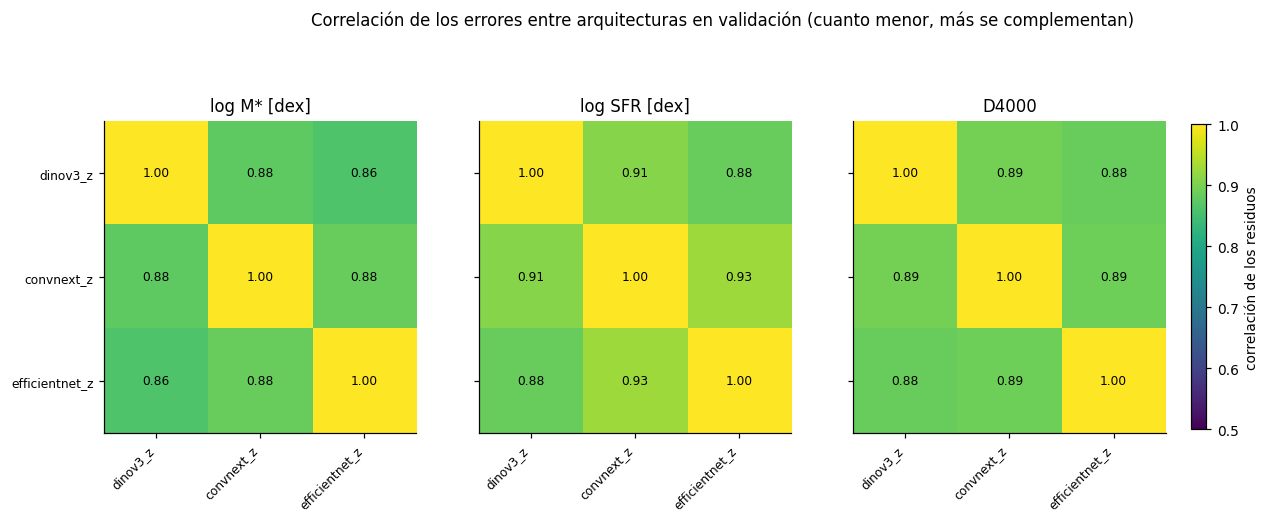

,error medio de los miembros,ambigüedad,error del ensamble,ganancia relativa
propiedad,,,,
M*,0.0262,0.0025,0.0238,0.0934
SFR,0.2284,0.0150,0.2134,0.0656
D4000,0.0801,0.0061,0.0740,0.0758


In [6]:
correlaciones = ensambles.correlacion_residuos(P_VAL, Y_VAL)
minimo_corr = float(min(0.5, np.floor(10 * correlaciones.min()) / 10))
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for k, (eje, matriz, t) in enumerate(zip(ejes, correlaciones, OBJETIVOS)):
    imagen = eje.imshow(matriz, vmin=minimo_corr, vmax=1, cmap="viridis")
    eje.set(xticks=range(len(FAMILIAS_HETEROGENEO)), yticks=range(len(FAMILIAS_HETEROGENEO)), title=NOMBRES[t])
    eje.set_xticklabels(FAMILIAS_HETEROGENEO, rotation=45, ha="right", fontsize=8)
    if k == 0:
        eje.set_yticklabels(FAMILIAS_HETEROGENEO, fontsize=8)
    for i in range(len(FAMILIAS_HETEROGENEO)):
        for j in range(len(FAMILIAS_HETEROGENEO)):
            eje.text(j, i, f"{matriz[i, j]:.2f}", ha="center", va="center", fontsize=8, color="w" if matriz[i, j] < (minimo_corr + 1) / 2 else "k")
fig.colorbar(imagen, ax=ejes, shrink=0.75, pad=0.02, label="correlación de los residuos")
plt.suptitle("Correlación de los errores entre arquitecturas en validación (cuanto menor, más se complementan)", y=1.0); plt.show()
AMBIGUEDAD = ensambles.descomposicion_ambiguedad(P_VAL, Y_VAL, ESCALA, nombres_objetivos=[CORTO[t] for t in OBJETIVOS]).set_index("propiedad")
AMBIGUEDAD["ganancia relativa"] = AMBIGUEDAD["ambigüedad"] / AMBIGUEDAD["error medio de los miembros"]
display(AMBIGUEDAD.round(4))

Los errores de las tres familias están muy correlacionados: de 0.86 a 0.88 en la masa, de 0.88 a 0.93 en la SFR y de 0.88 a 0.89 en el D4000. Por eso la ganancia posible es modesta: la ambigüedad equivale al 9.3 % del error medio de los miembros en la masa, al 6.6 % en la SFR y al 7.6 % en el D4000. Es exactamente lo que el promedio uniforme gana sobre el error medio de sus miembros, y marca la escala de lo que pueden lograr los combinadores: un ajuste de pesos solo puede ir más lejos si encuentra galaxias o propiedades en las que una familia es claramente mejor que las demás.

## 6. Ensamble heterogéneo 1: mezcla convexa

La mezcla convexa predice cada propiedad como un promedio ponderado de las familias, con pesos no negativos que suman uno, de modo que la predicción nunca queda fuera del intervalo que abarcan sus miembros. Los pesos se obtienen minimizando el error normalizado en la reserva más una penalización que los acerca al promedio uniforme: con una penalización grande se recupera el promedio simple, y sin penalización los pesos siguen solo al error. Esta penalización λ y el alcance de los pesos son los hiperparámetros que optimizamos: con alcance **por propiedad** cada una tiene sus propios pesos (por ejemplo, la masa puede apoyarse en una familia y la SFR en otra), y con alcance **global** las tres comparten los mismos.

| Hiperparámetro | Valores | Qué controla |
|---|---|---|
| Penalización λ | 0, 0.001, 0.01, 0.1, 1, 10 | Cuánto se acercan los pesos al promedio uniforme; la misma rejilla del ensamble homogéneo de Luz |
| Alcance de los pesos | por propiedad, global | Si cada propiedad tiene sus propios pesos |

Evaluamos las doce combinaciones con validación cruzada anidada: en cada pliegue externo, la combinación se elige con los otros pliegues y se mide en el reservado. El resultado es una predicción fuera de pliegue para cada galaxia y cada repetición. Al final ajustamos los pesos con toda la validación y los aplicamos a las predicciones de prueba de los miembros, sin evaluarlas.

Validación anidada de la mezcla convexa: criterio 0.1037 ± 0.0002 entre repeticiones · 8 s
Configuración elegida con toda la reserva: {'lambda': 0.01, 'alcance': 'por_objetivo'}
Configuración elegida en cada pliegue externo: {('por_objetivo', 0.0): 1, ('por_objetivo', 0.001): 2, ('por_objetivo', 0.01): 7, ('por_objetivo', 0.1): 5}


,tipo,lambda,alcance,criterio
0,mezcla_convexa,0.010,por_objetivo,0.1031
1,mezcla_convexa,0.001,por_objetivo,0.1031
2,mezcla_convexa,0.000,por_objetivo,0.1032
3,mezcla_convexa,0.001,global,0.1033
4,mezcla_convexa,0.000,global,0.1033
5,mezcla_convexa,0.010,global,0.1033


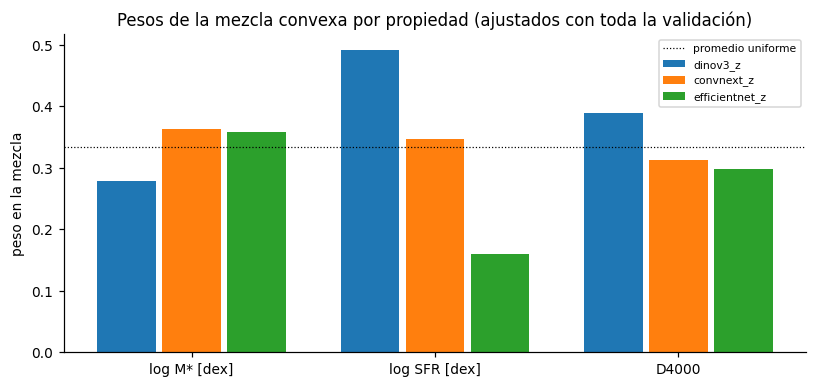

In [7]:
CANDIDATOS_H1 = [{"tipo": "mezcla_convexa", "lambda": l, "alcance": a} for a in ("por_objetivo", "global") for l in (0.0, 1e-3, 1e-2, 1e-1, 1.0, 10.0)]
inicio = time.time()
ANIDADA_H1 = ensambles.validacion_anidada(P_VAL, Y_VAL, None, ESCALA, candidatos=CANDIDATOS_H1, pliegues_externos=PLIEGUES_EXTERNOS,
                                          repeticiones=REPETICIONES, pliegues_internos=PLIEGUES_INTERNOS, semilla=SEMILLA_ANIDADA, n_trabajos=N_TRABAJOS)
SEGUNDOS_ANIDADA_H1 = time.time() - inicio
inicio = time.time()
CONFIG_H1, PRUEBAS_H1 = ensambles.buscar_configuracion(P_VAL, Y_VAL, None, ESCALA, candidatos=CANDIDATOS_H1, pliegues_internos=PLIEGUES_EXTERNOS,
                                                       semilla=SEMILLA_ANIDADA)
PESOS_H1 = ensambles.pesos_mezcla_convexa(P_VAL, Y_VAL, ESCALA, CONFIG_H1["lambda"], CONFIG_H1["alcance"])
PRED_PRUEBA_H1 = ensambles.aplicar_pesos(P_PRUEBA, PESOS_H1)        # se guarda sin evaluar
SEGUNDOS_FINAL_H1 = time.time() - inicio
print(f"Validación anidada de la mezcla convexa: criterio {ANIDADA_H1['criterio_medio']:.4f} ± {ANIDADA_H1['criterio_desviacion']:.4f} entre repeticiones · {SEGUNDOS_ANIDADA_H1:.0f} s")
print("Configuración elegida con toda la reserva:", {k: v for k, v in CONFIG_H1.items() if k != "tipo"})
print("Configuración elegida en cada pliegue externo:", ANIDADA_H1["configuraciones"].groupby(["alcance", "lambda"]).size().to_dict())
display(PRUEBAS_H1.head(6).round(5))
fig, eje = plt.subplots(figsize=(7.5, 3.6))
ancho = 0.8 / len(FAMILIAS_HETEROGENEO)
for i, f in enumerate(FAMILIAS_HETEROGENEO):
    eje.bar(np.arange(3) + i * ancho, PESOS_H1[i], ancho * 0.9, label=f)
eje.set(xticks=np.arange(3) + ancho * (len(FAMILIAS_HETEROGENEO) - 1) / 2, xticklabels=[NOMBRES[t] for t in OBJETIVOS], ylabel="peso en la mezcla",
        title="Pesos de la mezcla convexa por propiedad (ajustados con toda la validación)")
eje.axhline(1 / len(FAMILIAS_HETEROGENEO), color="k", ls=":", lw=0.8, label="promedio uniforme"); eje.legend(fontsize=7)
plt.tight_layout(); plt.show()

La mezcla convexa alcanza un criterio de 0.1037 en la validación anidada, con una variación de solo 0.0002 entre repeticiones. La búsqueda eligió siempre pesos por propiedad, y la penalización λ = 0.01 en 7 de los 15 pliegues externos, seguida de 0.1 en 5; con toda la validación también eligió λ = 0.01. Las seis mejores configuraciones difieren en dos diezmilésimas como máximo (de 0.1031 a 0.1033), así que el resultado no depende de la elección exacta de λ. Los pesos siguen lo que cada familia hace mejor. En la SFR, DINOv3 recibe casi la mitad del peso (0.49) y EfficientNet solo 0.16; en la masa, ConvNeXt y EfficientNet reciben 0.36 cada una y DINOv3 0.28; en el D4000 los pesos quedan cerca del promedio uniforme (0.39, 0.31 y 0.30).

## 7. Ensamble heterogéneo 2: meta-aprendiz

El meta-aprendiz recibe las predicciones de todas las familias para las tres propiedades y aprende a **corregir el promedio uniforme**: en lugar de predecir la propiedad desde cero, predice cuánto hay que sumar al promedio de los miembros. Así, cuando se regulariza con fuerza, el resultado se acerca al promedio y no a una constante, y un meta-aprendiz flexible no puede empeorar mucho a un promedio razonable. Darle las tres propiedades a la vez es una decisión nuestra, no una recomendación de la literatura: las tres están relacionadas (la SFR es la sSFR más la masa) y un error en la masa suele arrastrar el de la SFR. En el meta-aprendiz Ridge, la búsqueda decide si conviene esta opción o la que usa solo la propiedad correspondiente.

Optuna (Akiba et al. 2019) elige el tipo de meta-aprendiz y sus hiperparámetros con el muestreo bayesiano TPE, dentro de la validación cruzada anidada.

| Hiperparámetro | Espacio de búsqueda | Qué controla |
|---|---|---|
| Tipo de meta-aprendiz | regresión lineal con pesos no negativos; red elástica con pesos no negativos; Ridge sobre la corrección del promedio; bosque de gradiente poco profundo sobre la corrección | Familia del combinador; los dos primeros se parecen a la mezcla convexa pero con intercepto y sin la restricción de suma uno, lo que les permite corregir la compresión hacia el centro |
| α de la red elástica | 10⁻⁴ a 1 (logarítmica) | Regularización |
| Relación L1 de la red elástica | 0.1 a 0.9 | Mezcla entre selección de miembros y encogimiento |
| α de Ridge | 0.1 a 10⁴ (logarítmica) | Regularización |
| Entradas de Ridge | las tres propiedades; solo la propiedad correspondiente | Si el combinador ve los errores de las otras propiedades |
| Desacuerdo entre familias | sí, no | Si recibe como entrada la desviación entre los miembros, una medida de su incertidumbre; Ting y Witten (1999) encontraron, en clasificación, que el meta-aprendiz funciona mejor cuando recibe la confianza de los miembros |
| Redshift espectroscópico | sí, no (solo en la pista `con_redshift`) | Si recibe el redshift para que la corrección dependa de la distancia |
| Profundidad, tasa de aprendizaje e iteraciones del bosque | 2 a 3, 0.02 a 0.2, 30 a 150 | Flexibilidad del bosque; con 1,261 galaxias esperamos que sobreajuste, y la validación anidada lo comprobará |

In [8]:
def proponer_stacking(prueba):
    tipo = prueba.suggest_categorical("tipo", ["lineal_positivo", "elastica_positiva", "ridge_correccion", "bosque_residual"])
    usar_z = prueba.suggest_categorical("usar_z", [True, False]) if (REDSHIFT_EN_META and tipo in ("ridge_correccion", "bosque_residual")) else False
    if tipo == "lineal_positivo":
        return {"tipo": tipo}
    if tipo == "elastica_positiva":
        return {"tipo": tipo, "alpha": prueba.suggest_float("alpha_elastica", 1e-4, 1.0, log=True), "l1_ratio": prueba.suggest_float("l1_ratio", 0.1, 0.9)}
    if tipo == "ridge_correccion":
        return {"tipo": tipo, "alpha": prueba.suggest_float("alpha_ridge", 0.1, 1e4, log=True),
                "entradas": prueba.suggest_categorical("entradas", ["todas", "misma_propiedad"]), "usar_z": usar_z,
                "usar_desacuerdo": prueba.suggest_categorical("usar_desacuerdo", [True, False])}
    return {"tipo": tipo, "profundidad": prueba.suggest_int("profundidad", 2, 3), "tasa": prueba.suggest_float("tasa", 0.02, 0.2, log=True),
            "iteraciones": prueba.suggest_int("iteraciones", 30, 150), "usar_z": usar_z, "usar_desacuerdo": prueba.suggest_categorical("usar_desacuerdo_bosque", [True, False])}

Z_META_VAL = Z_VAL if REDSHIFT_EN_META else None
Z_META_PRUEBA = Z_PRUEBA if REDSHIFT_EN_META else None
inicio = time.time()
ANIDADA_H2 = ensambles.validacion_anidada(P_VAL, Y_VAL, Z_META_VAL, ESCALA, proponer=proponer_stacking, pliegues_externos=PLIEGUES_EXTERNOS,
                                          repeticiones=REPETICIONES, pliegues_internos=PLIEGUES_INTERNOS, n_pruebas=PRUEBAS_STACKING,
                                          semilla=SEMILLA_ANIDADA, n_trabajos=N_TRABAJOS)
SEGUNDOS_ANIDADA_H2 = time.time() - inicio
inicio = time.time()
CONFIG_H2, PRUEBAS_H2 = ensambles.buscar_configuracion(P_VAL, Y_VAL, Z_META_VAL, ESCALA, proponer=proponer_stacking, pliegues_internos=PLIEGUES_EXTERNOS,
                                                       n_pruebas=PRUEBAS_STACKING, semilla=SEMILLA_ANIDADA)
PRED_PRUEBA_H2 = ensambles.ajustar_predecir(CONFIG_H2, P_VAL, Y_VAL, Z_META_VAL, P_PRUEBA, Z_META_PRUEBA, ESCALA)   # se guarda sin evaluar
SEGUNDOS_FINAL_H2 = time.time() - inicio
print(f"Validación anidada del meta-aprendiz: criterio {ANIDADA_H2['criterio_medio']:.4f} ± {ANIDADA_H2['criterio_desviacion']:.4f} entre repeticiones · {SEGUNDOS_ANIDADA_H2:.0f} s")
print("Configuración elegida con toda la reserva:", {k: (round(v, 5) if isinstance(v, float) else v) for k, v in CONFIG_H2.items()})
print("Tipo de meta-aprendiz elegido en cada pliegue externo:", ANIDADA_H2["configuraciones"].tipo.value_counts().to_dict())
display(PRUEBAS_H2.head(8).round(5))

Validación anidada del meta-aprendiz: criterio 0.1046 ± 0.0003 entre repeticiones · 8 s
Configuración elegida con toda la reserva: {'tipo': 'bosque_residual', 'profundidad': 2, 'tasa': 0.02205, 'iteraciones': 148, 'usar_z': True, 'usar_desacuerdo': False}
Tipo de meta-aprendiz elegido en cada pliegue externo: {'elastica_positiva': 6, 'ridge_correccion': 5, 'bosque_residual': 4}


,tipo,alpha,l1_ratio,criterio,entradas,usar_z,usar_desacuerdo,profundidad,tasa,iteraciones
0,bosque_residual,NaN,NaN,0.1031,NaN,True,False,2.0,0.0221,148.0
1,elastica_positiva,0.0047,0.2071,0.1032,NaN,NaN,NaN,NaN,NaN,NaN
2,elastica_positiva,0.0080,0.1455,0.1032,NaN,NaN,NaN,NaN,NaN,NaN
3,elastica_positiva,0.0029,0.1823,0.1032,NaN,NaN,NaN,NaN,NaN,NaN
4,elastica_positiva,0.0024,0.2376,0.1032,NaN,NaN,NaN,NaN,NaN,NaN
5,elastica_positiva,0.0089,0.3018,0.1032,NaN,NaN,NaN,NaN,NaN,NaN
6,elastica_positiva,0.0019,0.2374,0.1032,NaN,NaN,NaN,NaN,NaN,NaN
7,elastica_positiva,0.0081,0.4380,0.1032,NaN,NaN,NaN,NaN,NaN,NaN


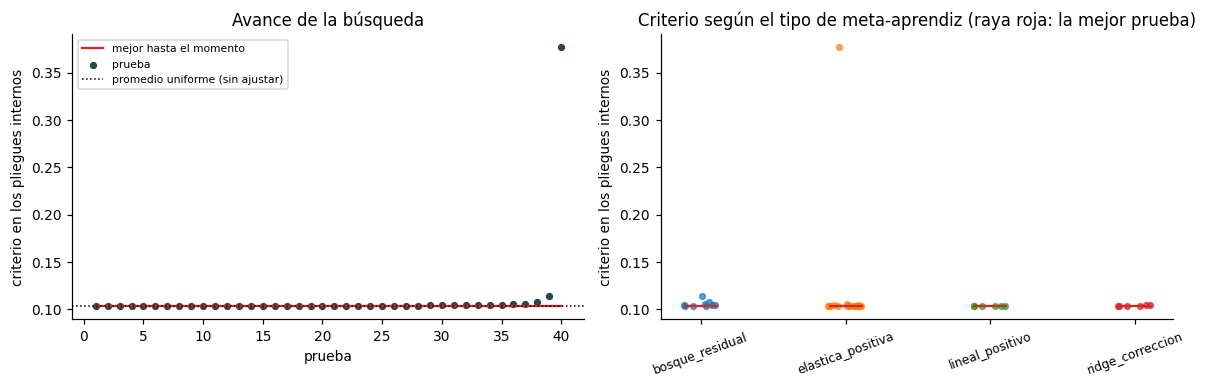

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
orden = np.arange(1, len(PRUEBAS_H2) + 1)
criterios_en_orden = PRUEBAS_H2.sort_index().criterio.to_numpy()
ejes[0].plot(orden, pd.Series(criterios_en_orden).cummin(), color="C3", label="mejor hasta el momento")
ejes[0].scatter(orden, criterios_en_orden, s=14, color="#264653", label="prueba")
ejes[0].axhline(ensambles.criterio(Y_VAL, PROMEDIO_FAMILIAS_VAL, ESCALA), color="k", ls=":", lw=1, label="promedio uniforme (sin ajustar)")
ejes[0].set(xlabel="prueba", ylabel="criterio en los pliegues internos", title="Avance de la búsqueda"); ejes[0].legend(fontsize=7)
tipos = sorted(PRUEBAS_H2.tipo.unique())
for i, tipo in enumerate(tipos):
    g = PRUEBAS_H2[PRUEBAS_H2.tipo == tipo]
    ejes[1].scatter(np.full(len(g), i) + np.random.default_rng(0).uniform(-0.12, 0.12, len(g)), g.criterio, s=14, alpha=0.7)
    ejes[1].scatter(i, g.criterio.min(), marker="_", s=500, color="C3")
ejes[1].set_xticks(range(len(tipos)), tipos, rotation=20, fontsize=8)
ejes[1].set(ylabel="criterio en los pliegues internos", title="Criterio según el tipo de meta-aprendiz (raya roja: la mejor prueba)")
plt.tight_layout(); plt.show()

El meta-aprendiz llega a 0.1046 ± 0.0003, un poco peor que la mezcla convexa y que el propio promedio uniforme. La búsqueda muestra por qué: casi todas las configuraciones, de los cuatro tipos, quedan en el mismo valor que el promedio uniforme sin ajustar (línea punteada), alrededor de 0.103 en los pliegues internos, y las pocas que se separan lo hacen hacia arriba, como una red elástica con regularización fuerte que llega a 0.38. Con toda la validación, Optuna eligió un bosque de gradiente de profundidad 2 con el redshift como entrada, pero en los pliegues externos el tipo elegido cambia (red elástica en 6, Ridge en 5 y bosque en 4). Ninguna forma de corregir el promedio es claramente mejor, y la que gana en cada partición lo hace por ruido: con 1,261 galaxias y miembros tan correlacionados, no hay una corrección sistemática que aprender.

## 8. Los dos ensambles frente a sus miembros

Comparamos en validación los dos ensambles con el mejor miembro y con el promedio simple de las familias. Para los ensambles usamos sus predicciones fuera de pliegue, de modo que ninguna galaxia fue predicha por un combinador ajustado con su propia etiqueta; el criterio es el promedio de las repeticiones y su desviación indica cuánto cambia con la partición. La diferencia con el mejor miembro se acompaña de un intervalo del 95 % por *bootstrap* pareado sobre la pérdida por galaxia, promediada entre repeticiones. Es una comparación de desarrollo: las redes ya usaron la validación para elegir su época, y la evaluación independiente es la del conjunto de prueba en el cuaderno final.

,criterio,desviación entre repeticiones,MSE normalizado M*,MSE normalizado SFR,MSE normalizado D4000,Δ con el mejor miembro,IC 95 %
modelo,,,,,,,
Heterogéneo 1: mezcla convexa,0.1037,0.0002,0.0237,0.2131,0.0742,-0.0044,"[-0.0074, -0.0015]"
Promedio simple de las familias,0.1038,no aplica,0.0238,0.2134,0.0740,-0.0044,"[-0.0080, -0.0008]"
Heterogéneo 2: meta-aprendiz,0.1046,0.0003,0.0236,0.2155,0.0745,-0.0035,"[-0.0066, -0.0005]"
Mejor miembro: dinov3_z,0.1081,no aplica,0.0278,0.2185,0.0780,0.0000,"[+0.0000, +0.0000]"


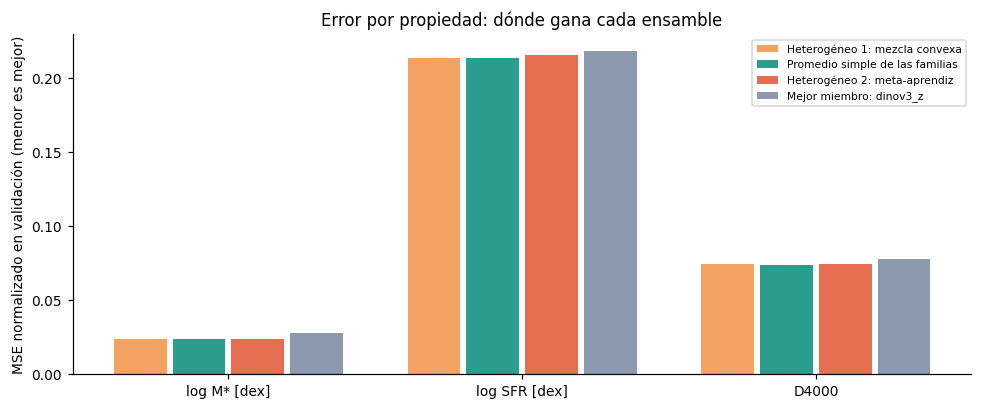

In [10]:
def perdida_media_oof(resultado):
    return np.mean([ensambles.perdida_por_galaxia(Y_VAL, o, ESCALA) for o in resultado["oof_por_repeticion"]], axis=0)

def criterio_propiedades_oof(resultado):
    return np.mean([ensambles.criterio_por_propiedad(Y_VAL, o, ESCALA) for o in resultado["oof_por_repeticion"]], axis=0)

PERDIDA_MEJOR = ensambles.perdida_por_galaxia(Y_VAL, VAL.media(MEJOR_MIEMBRO), ESCALA)
candidatos = {f"Mejor miembro: {MEJOR_MIEMBRO}": (PERDIDA_MEJOR, ensambles.criterio_por_propiedad(Y_VAL, VAL.media(MEJOR_MIEMBRO), ESCALA), np.nan),
              "Promedio simple de las familias": (ensambles.perdida_por_galaxia(Y_VAL, PROMEDIO_FAMILIAS_VAL, ESCALA),
                                                  ensambles.criterio_por_propiedad(Y_VAL, PROMEDIO_FAMILIAS_VAL, ESCALA), np.nan),
              NOMBRE_H1: (perdida_media_oof(ANIDADA_H1), criterio_propiedades_oof(ANIDADA_H1), ANIDADA_H1["criterio_desviacion"]),
              NOMBRE_H2: (perdida_media_oof(ANIDADA_H2), criterio_propiedades_oof(ANIDADA_H2), ANIDADA_H2["criterio_desviacion"])}
generador = np.random.default_rng(0)
indices_bootstrap = generador.integers(0, len(Y_VAL), (N_REMUESTREOS, len(Y_VAL)))
filas = []
for nombre, (perdida, por_propiedad, desviacion) in candidatos.items():
    d = perdida - PERDIDA_MEJOR
    medias = d[indices_bootstrap].mean(1)
    filas.append({"modelo": nombre, "criterio": perdida.mean(), "desviación entre repeticiones": desviacion,
                  **{f"MSE normalizado {CORTO[t]}": v for t, v in zip(OBJETIVOS, por_propiedad)},
                  "Δ con el mejor miembro": d.mean(), "IC 95 %": f"[{np.quantile(medias, 0.025):+.4f}, {np.quantile(medias, 0.975):+.4f}]"})
RESUMEN_HETEROGENEOS = pd.DataFrame(filas).set_index("modelo").sort_values("criterio")
display(RESUMEN_HETEROGENEOS.round(4).fillna({"desviación entre repeticiones": "no aplica"}))

fig, eje = plt.subplots(figsize=(9, 3.8))
ancho = 0.8 / len(RESUMEN_HETEROGENEOS)
colores = {"Mejor miembro": "#8d99ae", "Promedio simple": "#2a9d8f", "Heterogéneo 1": "#f4a261", "Heterogéneo 2": "#e76f51"}
for i, (nombre, fila) in enumerate(RESUMEN_HETEROGENEOS.iterrows()):
    color = next(v for k, v in colores.items() if nombre.startswith(k))
    eje.bar(np.arange(3) + i * ancho, [fila[f"MSE normalizado {CORTO[t]}"] for t in OBJETIVOS], ancho * 0.9, color=color, label=nombre)
eje.set(xticks=np.arange(3) + ancho * (len(RESUMEN_HETEROGENEOS) - 1) / 2, xticklabels=[NOMBRES[t] for t in OBJETIVOS],
        ylabel="MSE normalizado en validación (menor es mejor)", title="Error por propiedad: dónde gana cada ensamble")
eje.legend(fontsize=7); plt.tight_layout(); plt.show()

Los dos ensambles heterogéneos mejoran al mejor miembro con diferencias significativas: la mezcla convexa en 0.0044 (IC del 95 % de −0.0074 a −0.0015) y el meta-aprendiz en 0.0035 (de −0.0066 a −0.0005). La gráfica muestra que la mejora está sobre todo en la masa, donde el MSE normalizado baja 15 % (de 0.0278 a 0.0237), y en el D4000 (5 %, de 0.0780 a 0.0742), y menos en la SFR (2.5 %, de 0.2185 a 0.2131). Sin embargo, la mezcla convexa no se distingue del promedio simple de las familias (0.1037 contra 0.1038). Lo que mejora al mejor miembro es la combinación de arquitecturas; aprender los pesos casi no agrega nada a promediarlas. Ninguno de los dos combinadores cumple, entonces, la condición que planteamos en la sección 4: superar claramente al promedio simple.

## 9. Qué aporta cada arquitectura

Para saber qué familia sostiene a cada ensamble, volvemos a ajustar su combinador sin ella, con la configuración elegida y cinco pliegues, y medimos cuánto empeora el criterio en validación. Un aumento grande indica una familia que aporta información que las demás no tienen; uno cercano a cero, una familia que el ensamble podría omitir para ahorrar costo. Después agregamos las familias de una en una, en el orden de su aporte, para ver si los rendimientos son decrecientes, lo que ayuda a decidir cuántas redes vale la pena ejecutar por galaxia.

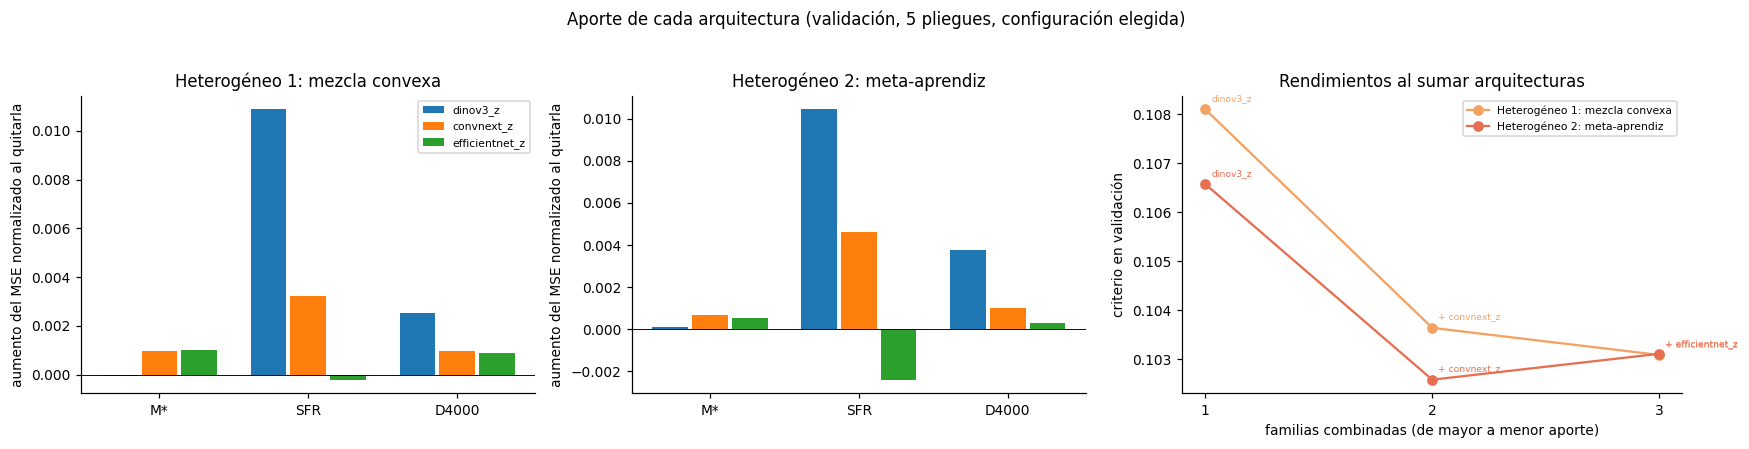

aumento M*  aumento SFR  aumento D4000  aumento del criterio
ensamble                      familia                                                                     
Heterogéneo 1: mezcla convexa dinov3_z           -0.0000       0.0109         0.0025                0.0045
                              convnext_z          0.0010       0.0032         0.0010                0.0017
                              efficientnet_z      0.0010      -0.0002         0.0009                0.0006
Heterogéneo 2: meta-aprendiz  dinov3_z            0.0001       0.0105         0.0038                0.0048
                              convnext_z          0.0007       0.0046         0.0010                0.0021
                              efficientnet_z      0.0005      -0.0024         0.0003               -0.0005

In [11]:
CONFIGS_FINALES = {NOMBRE_H1: {"tipo": "mezcla_convexa", "lambda": CONFIG_H1["lambda"], "alcance": CONFIG_H1["alcance"]}, NOMBRE_H2: CONFIG_H2}
filas, CURVAS = [], {}
for nombre, config in CONFIGS_FINALES.items():
    oof_completo, criterio_completo = ensambles.validar_configuracion(config, P_VAL, Y_VAL, Z_META_VAL, ESCALA, PLIEGUES_EXTERNOS, SEMILLA_ANIDADA)
    referencia = ensambles.criterio_por_propiedad(Y_VAL, oof_completo, ESCALA)
    for i, f in enumerate(FAMILIAS_HETEROGENEO):
        resto = [j for j in range(len(FAMILIAS_HETEROGENEO)) if j != i]
        oof, criterio_sin = ensambles.validar_configuracion(config, P_VAL[resto], Y_VAL, Z_META_VAL, ESCALA, PLIEGUES_EXTERNOS, SEMILLA_ANIDADA)
        por_propiedad = ensambles.criterio_por_propiedad(Y_VAL, oof, ESCALA) - referencia
        filas.append({"ensamble": nombre, "familia": f, **{f"aumento {CORTO[t]}": v for t, v in zip(OBJETIVOS, por_propiedad)},
                      "aumento del criterio": criterio_sin - criterio_completo})
APORTE = pd.DataFrame(filas)
for nombre, config in CONFIGS_FINALES.items():
    orden = list(APORTE[APORTE.ensamble == nombre].sort_values("aumento del criterio", ascending=False).familia)
    posiciones = [FAMILIAS_HETEROGENEO.index(f) for f in orden]
    CURVAS[nombre] = (orden, [ensambles.validar_configuracion(config, P_VAL[posiciones[:n]], Y_VAL, Z_META_VAL, ESCALA, PLIEGUES_EXTERNOS, SEMILLA_ANIDADA)[1]
                              for n in range(1, len(orden) + 1)])

fig, ejes = plt.subplots(1, 3, figsize=(16, 3.9), gridspec_kw={"width_ratios": [1, 1, 1.1]})
ancho = 0.8 / len(FAMILIAS_HETEROGENEO)
for eje, nombre in zip(ejes[:2], CONFIGS_FINALES):
    a = APORTE[APORTE.ensamble == nombre].set_index("familia")
    for i, f in enumerate(FAMILIAS_HETEROGENEO):
        eje.bar(np.arange(3) + i * ancho, [a.loc[f, f"aumento {CORTO[t]}"] for t in OBJETIVOS], ancho * 0.9, label=f)
    eje.axhline(0, color="k", lw=0.6)
    eje.set(xticks=np.arange(3) + ancho * (len(FAMILIAS_HETEROGENEO) - 1) / 2, xticklabels=[CORTO[t] for t in OBJETIVOS],
            ylabel="aumento del MSE normalizado al quitarla", title=nombre)
ejes[0].legend(fontsize=7)
for nombre, color in zip(CURVAS, ("#f4a261", "#e76f51")):
    orden, curva = CURVAS[nombre]
    ejes[2].plot(range(1, len(orden) + 1), curva, "o-", color=color, label=nombre)
    for n, (f, v) in enumerate(zip(orden, curva), 1):
        ejes[2].annotate(f if n == 1 else f"+ {f}", (n, v), textcoords="offset points", xytext=(4, 5), fontsize=6, color=color)
ejes[2].set(xticks=range(1, len(FAMILIAS_HETEROGENEO) + 1), xlabel="familias combinadas (de mayor a menor aporte)",
            ylabel="criterio en validación", title="Rendimientos al sumar arquitecturas"); ejes[2].legend(fontsize=7)
plt.suptitle("Aporte de cada arquitectura (validación, 5 pliegues, configuración elegida)", y=1.03); plt.tight_layout(); plt.show()
display(APORTE.set_index(["ensamble", "familia"]).round(4))

DINOv3 es la familia que más sostiene a los dos ensambles: quitarla aumenta el criterio entre 0.0045 y 0.0048, sobre todo por la SFR (0.011) y el D4000. Quitar ConvNeXt cuesta entre 0.0017 y 0.0021, repartido entre las tres propiedades. EfficientNet-B3 casi no aporta: sin ella, el criterio de la mezcla convexa sube solo 0.0006 y el del meta-aprendiz incluso baja 0.0005, y en la SFR su ausencia mejora a los dos. La curva de la derecha lo confirma. En la mezcla convexa, pasar de DINOv3 sola a DINOv3 y ConvNeXt baja el criterio de 0.1081 a 0.1036, y agregar EfficientNet solo lo lleva a 0.1031; en el meta-aprendiz, agregarla lo empeora de 0.1026 a 0.1031. Estos valores usan la configuración elegida con toda la validación y son un poco optimistas frente a la validación anidada, pero sirven para comparar entre sí. Quitar EfficientNet ahorraría poco tiempo de uso (1.2 de 10.6 ms por galaxia, porque casi todo el costo es de DINOv3), aunque simplificaría el modelo sin perder precisión. No lo hacemos porque los miembros se fijaron antes de ver estos resultados, y lo dejamos como recomendación.

## 10. Exportación para la comparación final

Guardamos lo que necesita el cuaderno de comparación final, en la carpeta `ensambles_heterogeneos`. De cada ensamble se guardan sus predicciones fuera de pliegue de validación, una por repetición, y sus predicciones de prueba, con el combinador ajustado con toda la validación. Un archivo de configuración reúne las familias, los hiperparámetros elegidos, los pesos de la mezcla, los criterios de cada repetición, los tiempos de ajuste, el aporte de cada familia y una huella de las predicciones de los miembros. El cuaderno final recalcula esa huella y se detiene si no coincide, de modo que no se puedan mezclar ensambles ajustados con otras predicciones.

In [12]:
def a_json(valor):
    if isinstance(valor, np.ndarray):
        return valor.tolist()
    return valor.item() if hasattr(valor, "item") else str(valor)

for archivo, resultado, prediccion_prueba in ((ARCHIVO_H1, ANIDADA_H1, PRED_PRUEBA_H1), (ARCHIVO_H2, ANIDADA_H2, PRED_PRUEBA_H2)):
    predicciones.guardar_ensamble(CARPETA_HETEROGENEOS, PISTA, archivo, VAL.ids, resultado["oof_por_repeticion"], PRUEBA.ids, prediccion_prueba)
APORTE.to_csv(CARPETA_HETEROGENEOS / f"aporte_familias_{PISTA}.csv", index=False)
CONFIGURACION_EXPORTADA = {
    "pista": PISTA, "commit": COMMIT, "fecha_utc": datetime.now(timezone.utc).isoformat(), "familias": FAMILIAS_HETEROGENEO,
    "semillas": {f: VAL.semillas[f] for f in FAMILIAS_HETEROGENEO}, "huella_miembros": HUELLA_MIEMBROS,
    "galaxias": {"Validation": len(VAL.ids), "Test": len(PRUEBA.ids)},
    "validacion_anidada": {"pliegues_externos": PLIEGUES_EXTERNOS, "repeticiones": REPETICIONES, "pliegues_internos": PLIEGUES_INTERNOS,
                           "pruebas_stacking": PRUEBAS_STACKING, "semilla": SEMILLA_ANIDADA},
    ARCHIVO_H1: {"nombre": NOMBRE_H1, "configuracion": CONFIG_H1, "pesos": PESOS_H1, "criterios": ANIDADA_H1["criterios"],
                 "criterio_medio": ANIDADA_H1["criterio_medio"], "criterio_desviacion": ANIDADA_H1["criterio_desviacion"],
                 "configuraciones_por_pliegue": ANIDADA_H1["configuraciones"].to_dict("records"),
                 "segundos_validacion_anidada": SEGUNDOS_ANIDADA_H1, "segundos_ajuste_final": SEGUNDOS_FINAL_H1},
    ARCHIVO_H2: {"nombre": NOMBRE_H2, "configuracion": CONFIG_H2, "criterios": ANIDADA_H2["criterios"],
                 "criterio_medio": ANIDADA_H2["criterio_medio"], "criterio_desviacion": ANIDADA_H2["criterio_desviacion"],
                 "configuraciones_por_pliegue": ANIDADA_H2["configuraciones"].to_dict("records"),
                 "segundos_validacion_anidada": SEGUNDOS_ANIDADA_H2, "segundos_ajuste_final": SEGUNDOS_FINAL_H2}}
(CARPETA_HETEROGENEOS / f"heterogeneos_{PISTA}.json").write_text(json.dumps(CONFIGURACION_EXPORTADA, indent=2, ensure_ascii=False, default=a_json))
display(pd.DataFrame([{"archivo": a.name, "kB": round(a.stat().st_size / 1024, 1)} for a in sorted(CARPETA_HETEROGENEOS.glob(f"*{PISTA}*"))]))

,archivo,kB
0,aporte_familias_con_redshift.csv,0.8
1,ens_con_redshift_h1_mezcla_convexa.csv,357.7
2,ens_con_redshift_h2_meta_aprendiz.csv,357.8
3,heterogeneos_con_redshift.json,9.3


## 11. Conclusiones

Los dos ensambles heterogéneos superan al mejor de sus miembros, DINOv3 con redshift, con diferencias significativas en validación: la mezcla convexa llega a 0.1037 y el meta-aprendiz a 0.1046, contra 0.1081. La mejora viene sobre todo de la masa y el D4000, donde ConvNeXt y EfficientNet complementan a DINOv3, y es menor en la SFR.

La ganancia la produce la combinación de arquitecturas y no el combinador. La mezcla convexa empata con el promedio simple de las tres familias, y el meta-aprendiz, más flexible, no encuentra ninguna corrección sistemática y elige un tipo distinto según la partición. La causa es la alta correlación de los errores de las tres familias (de 0.86 a 0.93), que limita la ganancia posible a entre 6.6 y 9.3 % del error medio de los miembros.

DINOv3 aporta la mayor parte del beneficio en la SFR y el D4000, y ConvNeXt en la masa. EfficientNet-B3 casi no aporta, y un ensamble de DINOv3 y ConvNeXt conservaría prácticamente toda la ganancia.

Guardamos las predicciones fuera de pliegue de validación y las de prueba de los dos ensambles, con su configuración y una huella de los miembros. La evaluación en prueba se hace una sola vez en `Avance5.24.ipynb`, después de registrar el modelo final.

## 12. Referencias

Akiba, T., Sano, S., Yanase, T., Ohta, T. y Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD*, 2623–2631.

Breiman, L. (1996). Stacked regressions. *Machine Learning*, 24(1), 49–64.

Cawley, G. C. y Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research*, 11, 2079–2107.

Krogh, A. y Vedelsby, J. (1995). Neural network ensembles, cross validation, and active learning. *Advances in Neural Information Processing Systems 7*, 231–238.

Singh, A. (2023, 14 de julio). Comprehensive guide to ensemble learning (with Python codes). *Analytics Vidhya*. https://www.analyticsvidhya.com/blog/2018/06/comprehensive-guide-for-ensemble-models/

Studer, S., Bui, T. B., Drescher, C., et al. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction*, 3, 392–413.

Ting, K. M. y Witten, I. H. (1999). Issues in stacked generalization. *Journal of Artificial Intelligence Research*, 10, 271–289.

Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.

La declaración de uso de IA y la contribución de cada integrante de todo el avance están al final de `Avance5.24.ipynb`.